In [37]:
# Script to simulate DF using fundamental signal components 
# 2026-09-13
# Morena 


using LinearAlgebra
using Plots
using SignalAnalysis
using FFTW

const MIC_NUMBER = 3
const SRCDOA_POINTS = 3
const BASELINE = 0.017 # to avoid spatial aliasing, calculated with fmax=10.088kHz, b<=[(c/fmax)/2 = lambda_min/2] 
const C = 343

# Signal simulation in which measured phase difference will be derived from and compared against simulated LUT
fs = 44100
f = 4000
Fmin = 2000
duration = 3
t = 0:1/fs:duration-1/fs
#theta_pre = rand()*2*(pi)
theta_pre = 0*(pi/180)
N = length(t)


tau1_21 = (BASELINE*sin((30*(pi/180)-theta_pre)))/C
tau1_31 = (BASELINE*cos(theta_pre))/C


f2 = 6000
f3 = 9500
source1 = sin.(2*pi*f .* t) .+ sin.(2*pi*f2 .* t) .+ sin.(2*pi*f3 .* t)


# Signals received by each microphone

sigMic1 = source1 .+ 0.01 .* randn(size(source1))
sigMic2 = sin.(2*pi*f .* (t .- tau1_21)) .+ 0.01 .* randn(size(source1))
sigMic3 = sin.(2*pi*f .* (t .- tau1_31)) .+ 0.01 .* randn(size(source1))


# Mic position set
mic = [zeros(MIC_NUMBER) for _ in 1:2]
mic[1][1] =  BASELINE/2
mic[1][3] = -BASELINE/2
mic[2][1] = -BASELINE*sqrt(3)/6
mic[2][2] =  BASELINE*sqrt(3)/3
mic[2][3] = -BASELINE*sqrt(3)/6

p1 = [mic[1][1], mic[2][1]]
p2 = [mic[1][2], mic[2][2]]
p3 = [mic[1][3], mic[2][3]]



@show theta_pre*(180/pi)

theta_pre * (180 / pi) = 0.0


0.0

The determined Angle of Arrival is 359.68 °, combined across 257 frames.


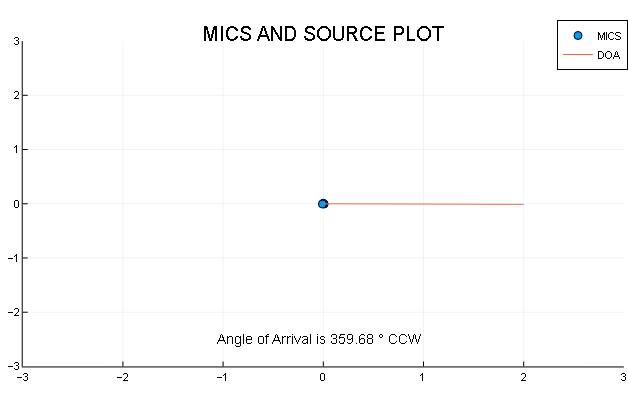

In [38]:
# Assumming the signals are not known from here, Analyse the signals.
# BROADBAND SIGNIFICANT PARAMETERs
Frame_len = 1024
Ns = length(sigMic1)
Hop = div(Frame_len, 2)
win = 0.5 .- 0.5 .* cos.(2π .* (0:Frame_len-1) ./ Frame_len)
Nf = 1 + div(Ns - Frame_len, Hop)
nb = div(Frame_len, 2) + 1
freqs = (0:nb-1) .* (fs / Frame_len)
inband = findall(j -> Fmin <= freqs[j] <= f, 1:nb)



# Frame analysis
AOA_estimates = Float64[]
angles = 0:0.01:359.99
thetas = angles .* (pi/180)
f_lut  = freqs[argmax(abs2.(rfft(win .* sigMic1[1:Frame_len]))[inband]) + first(inband) - 1]  # bin freq of the tone
lut12  = exp.(im*(-2)*pi*f_lut*BASELINE .* sin.((pi/6) .- thetas) ./ C)
lut13  = exp.(im*(-2)*pi*f_lut*BASELINE .* cos.(thetas) ./ C)

for fi in 1:Nf
    idx = (fi-1)*Hop .+ (1:Frame_len)
    S1f = rfft(win .* sigMic1[idx])
    S2f = rfft(win .* sigMic2[idx])
    S3f = rfft(win .* sigMic3[idx])

    _, local_idx = findmax(abs2.(S1f[inband]))
    b = inband[local_idx]

    measured12 = S2f[b]*conj(S1f[b])
    measured13 = S3f[b]*conj(S1f[b])

    costFn = angle.(lut12 .* conj(measured12)).^2 .+ angle.(lut13 .* conj(measured13)).^2
    push!(AOA_estimates, round(angles[argmin(costFn)], digits=2))
end


# Combine frame estimates. Angles wrap around 360°, so use circular statistics.
rad_estimates = deg2rad.(AOA_estimates)
sin_mean = mean(sin.(rad_estimates))
cos_mean = mean(cos.(rad_estimates))
AOA = round(mod(rad2deg(atan(sin_mean, cos_mean)), 360), digits=2)

println("The determined Angle of Arrival is $AOA °, combined across $(length(AOA_estimates)) frames.")

# Plot of the mics and the direction of arrival of the signal

plotly()

srcDOA = [zeros(SRCDOA_POINTS) for _ in 1:2]
for i in 1:SRCDOA_POINTS
    r = i-1
    srcDOA[1][i] = r*cos(AOA*(pi/180))
    srcDOA[2][i] = r*sin(AOA*(pi/180))
end

scatter(mic[1], mic[2], xlims=(-3, 3), ylims=(-3, 3), title="MICS AND SOURCE PLOT", label = "MICS")
plot!(srcDOA[1], srcDOA[2], label = "DOA")
aoa = text("Angle of Arrival is $AOA ° CCW", :black, :right, 10)
annotate!(1, -2.5, aoa)